<a href="https://colab.research.google.com/github/An-n-nie/SealSNP/blob/main/notebooks/SealSNP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uploading Files

In [2]:
#Import files stored in local computer
from google.colab import files
uploaded_files = {}

while True:
  attempt = files.upload()
  if not attempt:
    print("No files uploaded")
  else:
    uploaded_files.update(attempt)
    print(f"Successfully uploaded: {list(attempt.keys())}")

  ans = input("Do you want to upload more files? (yes/no): ").strip().lower()
  if ans not in ['y', 'yes']:
    break

Saving Hg_consensus_seq_all.fa to Hg_consensus_seq_all.fa
Saving Hg_genepop_r80p8.gen.txt to Hg_genepop_r80p8.gen.txt
Saving Hg.catalog.snps.csv to Hg.catalog.snps.csv
Successfully uploaded: ['Hg_consensus_seq_all.fa', 'Hg_genepop_r80p8.gen.txt', 'Hg.catalog.snps.csv']
Do you want to upload more files? (yes/no): no


In [3]:
#Install biopython to use later
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 19.7 MB/s  0:00:00


In [49]:
#Import libraries
from Bio import SeqIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix,classification_report,
                             ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, recall_score,
                             precision_score, f1_score)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

In [5]:
#Assign file
genepop_file = 'Hg_genepop_r80p8.gen.txt'
snp_catalog = 'Hg.catalog.snps.csv'

# Initial Inspection

In [6]:
#Inspect the genepop file

with open(genepop_file, 'r') as f:
  lines= f.readlines()
print("Total lines:", len(lines))

print("Inspect head/top rows")
for i, line in enumerate(lines[:30]):
  print(f"{i}: {line.rstrip()}")

print("Inspect the end")
for i, line in enumerate(lines[-10:], start=len(lines)-10):
  print(f"{i}: {line.rstrip()}")

Total lines: 262
Inspect head/top rows
0: Hg_genepop_r80p8
1: 52_20,82_17,86_26,126_8,134_39,194_35,198_9,209_31,294_34,372_23,372_25,372_44,396_17,424_41,463_21,504_34,505_28,606_30,615_17,756_33,756_38,776_44,795_10,802_28,806_17,840_39,844_19,873_17,888_21,914_44,931_42,951_39,968_32,1002_12,1047_43,1066_31,1066_42,1119_19,1289_8,1338_25,1357_18,1380_43,1380_44,1415_17,1446_28,1460_39,1473_14,1507_6,1507_40,1518_30,1556_36,1587_14,1593_8,1642_23,1644_28,1653_38,1663_43,1666_8,1703_32,1709_31,1738_41,1752_8,1761_17,1805_30,1816_14,1832_28,1855_38,1937_6,2053_26,2085_8,2087_33,2088_23,2093_39,2096_13,2100_24,2133_38,2138_17,2244_9,2253_12,2289_31,2295_30,2363_9,2364_15,2379_11,2399_28,2472_31,2495_24,2500_32,2530_24,2690_16,2734_34,2763_19,2785_16,2785_23,2795_23,2850_31,2865_40,2897_27,2918_20,2942_35,3018_39,3043_42,3073_24,3103_35,3117_35,3118_15,3128_8,3172_36,3300_17,3307_20,3320_28,3342_16,3357_25,3386_38,3423_19,3423_24,3438_10,3583_35,3603_39,3625_30,3683_15,3748_26,3775_35,38

In [7]:
#Inspect snp catalog
snp_df = pd.read_csv(snp_catalog)

print("Catalog shape:", snp_df.shape)
print(f"\nColumn names: {snp_df.columns.tolist()}")
display(snp_df.head())

Catalog shape: (42167, 7)

Column names: ['LocusID', 'Column', 'LikelihoodRatio', 'MajorAllele', 'AlternateAllele1', 'AlternateAllele2', 'AlternateAllele3']


,LocusID,Column,LikelihoodRatio,MajorAllele,AlternateAllele1,AlternateAllele2,AlternateAllele3
0,7,22,0.0,G,A,-,-
1,9,20,0.0,C,G,-,-
2,11,10,0.0,G,C,-,-
3,30,22,0.0,A,C,-,-
4,47,36,0.0,C,A,-,-


# Parsing the genepop file

In [8]:
# Extract marker names
with open(genepop_file, 'r') as f:
  genepop_lines = [line.strip() for line in f if line.strip()]

# 1st line = file title
file_title = genepop_lines[0]

# 2nd line = marker names
marker_names = [ marker.strip() for marker in genepop_lines[1].split(',')]

print("File title:", file_title)
print("Number of marker:", len(marker_names)) #expect 3,282 markers
print("First 10 markers:", marker_names[:10])
print("Last 10 markers:", marker_names[-10:])

File title: Hg_genepop_r80p8
Number of marker: 3282
First 10 markers: ['52_20', '82_17', '86_26', '126_8', '134_39', '194_35', '198_9', '209_31', '294_34', '372_23']
Last 10 markers: ['80737_10', '80765_36', '80775_15', '80776_38', '80817_21', '80843_17', '80847_41', '80853_34', '86967_31', '86967_34']


In [9]:
#extract individual and genotype codes

individual_ids = []
genotype_rows = []
population_blocks = []

current_block = 0

for line in genepop_lines[2:]:
  # identify population separaator
  if line.lower() == 'pop':
    current_block += 1
    continue

  #split individual ID from genotype data
  parts = line.split(',', 1)

  if len(parts) !=2:
    print("Unexpected line:", line[:100])
    continue

  individual_id = parts[0].strip()

  #extract genotyep codes
  genotype = parts[1].split()

  individual_ids.append(individual_id)
  genotype_rows.append(genotype)
  population_blocks.append(current_block)

# QC: Check the number of genotype values in every row
row_lengths = pd.Series([len(row) for row in genotype_rows],
                        index=individual_ids)

print("Expected markers:", len(marker_names))
print("\nGenotype values per individual:")
print(row_lengths.value_counts().sort_index())

print("\nRows with unexpected lengths:")
print(row_lengths[row_lengths != len(marker_names)] )

Expected markers: 3282

Genotype values per individual:
3282    251
3283      1
Name: count, dtype: int64

Rows with unexpected lengths:
Sab98_7X3    3283
dtype: int64


In [10]:
# Find the original line for the error

target_id = "Sab98_7X3"

for line in genepop_lines:
    if line.startswith(target_id + ","):
        raw_line = line
        break

parts = raw_line.split(",", 1)
tokens = parts[1].split()

print("Individual:", target_id)
print("Total genotype tokens:", len(tokens))
print("\nOriginal line (first 250 characters):")
print(raw_line[:250])

# Check whether any tokens have an unexpected format
print("\nTokens that are not exactly 4 digits:")
for i, token in enumerate(tokens):
    if len(token) != 4 or not token.isdigit():
        print(f"Position {i}: {repr(token)}")

print("\nFirst 15 tokens:")
print(tokens[:15])

print("\nLast 15 tokens:")
print(tokens[-15:])

Individual: Sab98_7X3
Total genotype tokens: 3283

Original line (first 250 characters):
Sab98_7X3,,	0404	0101	0204	0404	0103	0204	0202	0404	0101	0303	0303	0404	0303	0101	0303	0103	0303	0404	0303	0103	0404	0303	0303	0303	0303	0303	0404	0303	0101	0303	0202	0202	0103	0404	0101	0404	0202	0204	0303	0303	0202	0303	0202	0303	0404	0303	0202	010

Tokens that are not exactly 4 digits:
Position 0: ','

First 15 tokens:
[',', '0404', '0101', '0204', '0404', '0103', '0204', '0202', '0404', '0101', '0303', '0303', '0404', '0303', '0101']

Last 15 tokens:
['0404', '0303', '0303', '0202', '0303', '0103', '0404', '0204', '0404', '0303', '0404', '0202', '0103', '0000', '0000']


In [11]:
# error identified = double comma after the individual's ID

row_index = individual_ids.index(target_id) #Sab98_7X3

#Remove leading comma from target_id's genotype row
if genotype_rows[row_index][0]== ',':
  genotype_rows[row_index] = genotype_rows[row_index][1:]

#Verify all rows have same amount of markers
row_lengths = pd.Series([len(row) for row in genotype_rows],
                        index=individual_ids)

print("Genotype dimensions check:")
print(row_lengths.value_counts().sort_index())

assert (row_lengths == len(marker_names)).all()
print("\nCheck passed.")

Genotype dimensions check:
3282    252
Name: count, dtype: int64

Check passed.


In [12]:
#Create raw genotype-code matrix
x_genotype_codes = pd.DataFrame( genotype_rows, index=individual_ids,
                                columns=marker_names)

#Store individual metadata separately
metadata = pd.DataFrame({
    'individual_id': individual_ids,
    'population_block': population_blocks}).set_index('individual_id')

# Parsing QC

In [13]:
# Parsing Checks

assert x_genotype_codes.shape == (len(individual_ids), len(marker_names))

#Check duplicate individual IDs
print("\nDuplicate IDs:", x_genotype_codes.index.duplicated().sum())

#Check missing genotype codes
print("\nMissing genotype codes:",(x_genotype_codes == '0000').sum().sum())

#Check genotype code lengths
code_lengths = (x_genotype_codes.stack().str.len().value_counts())
print("\nCode lengths:\n", code_lengths)

#Check individuals in each original population block
print("\nIndividuals per population block:")
print(metadata['population_block'].value_counts().sort_index())


Duplicate IDs: 0

Missing genotype codes: 49374

Code lengths:
 4    827064
Name: count, dtype: int64

Individuals per population block:
population_block
1    32
2    33
3    34
4    28
5    29
6    32
7    32
8    32
Name: count, dtype: int64


In [14]:
#check that marker names match snp catalog

snp_df['marker_name'] = (snp_df['LocusID'].astype(str)
                             + '_' + snp_df['Column'].astype(str))

genepop_markers = set(marker_names)
catalog_markers = set(snp_df['marker_name'])

print("Genepop markers:", len(genepop_markers))
print("Unique catalog markers:", len(catalog_markers))

print("Markers in Genepop but not catalog:",
      len(genepop_markers - catalog_markers))

print("Markers in catalog but not Genepop:",
      len(catalog_markers - genepop_markers))

Genepop markers: 3282
Unique catalog markers: 42167
Markers in Genepop but not catalog: 0
Markers in catalog but not Genepop: 38885


In [15]:
# Calculate proportion of missing genotypes per individual
individual_missingness = ((x_genotype_codes == '0000').mean(axis=1))

# Create a summary table
missing_df = pd.DataFrame({'individual_id': x_genotype_codes.index,
                               'missing_count': (x_genotype_codes == '0000').sum(axis=1).values,
                               'missingness': individual_missingness.values})

# Sort from highest to lowest missingness
missing_df = missing_df.sort_values('missingness', ascending=False)

print("Overall missingness:")
print(missing_df['missingness'].describe().round(4))

print("\nTop individuals with the highest missingness:")
display(missing_df.head(15).round(4))

print("\nNumber of individuals exceeding missingness thresholds:")

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    count = (missing_df['missingness'] > threshold).sum()
    print(f">{threshold:.0%}: {count} individuals")

Overall missingness:
count    252.0000
mean       0.0597
std        0.1023
min        0.0012
25%        0.0067
50%        0.0192
75%        0.0715
max        0.7706
Name: missingness, dtype: float64

Top individuals with the highest missingness:


,individual_id,missing_count,missingness
105,Sab73_B100,2529,0.7706
127,Sab85_F126,2128,0.6484
43,Mus02_UMB023,2105,0.6414
34,Mus02_UMB004,1950,0.5941
132,Sab85_F208,1181,0.3598
35,Mus02_UMB005,1121,0.3416
88,Mus16_Hg812,1024,0.3120
109,Sab73_B204,963,0.2934
197,Sab04_S04-18,937,0.2855
93,Mus16_Hg824,902,0.2748



Number of individuals exceeding missingness thresholds:
>5%: 91 individuals
>10%: 43 individuals
>15%: 21 individuals
>20%: 18 individuals
>30%: 7 individuals
>50%: 4 individuals


In [16]:
# Calculate missingness for each marker
marker_missingness = ((x_genotype_codes == '0000')
                        .mean(axis=0).rename('missingness'))

print("Overall marker missingness:")
print(marker_missingness.describe().round(4))

print("\nMarkers with highest missingness:")
display(marker_missingness.sort_values(ascending=False).head(15).to_frame())

print("\nNumber of markers exceeding missingness thresholds:")

for threshold in [0.05, 0.10, 0.15, 0.20]:
    count = (marker_missingness > threshold).sum()
    print(f">{threshold:.0%}: {count} markers")

Overall marker missingness:
count    3282.0000
mean        0.0597
std         0.0230
min         0.0079
25%         0.0437
50%         0.0556
75%         0.0754
max         0.1508
Name: missingness, dtype: float64

Markers with highest missingness:


,missingness
73501_31,0.150794
53358_9,0.138889
54721_30,0.138889
44068_11,0.134921
80488_21,0.130952
69185_26,0.130952
65225_42,0.130952
25346_30,0.130952
60212_14,0.126984
2087_33,0.126984



Number of markers exceeding missingness thresholds:
>5%: 2084 markers
>10%: 149 markers
>15%: 1 markers
>20%: 0 markers


In [17]:
#Count unique alleles per marker to verify genotype alleles

# Split each four-digit genotype into two allele codes
allele_1 = x_genotype_codes.apply(lambda col: col.str[:2])

allele_2 = x_genotype_codes.apply(lambda col: col.str[2:])

# Combine both allele columns to find unique alleles per marker
allele_counts = {}

for marker in x_genotype_codes.columns:
    alleles = pd.concat([allele_1[marker], allele_2[marker] ])

    # Exclude missing allele codes
    alleles = alleles[alleles != '00']

    allele_counts[marker] = sorted(alleles.unique())

allele_summary = pd.DataFrame({
    'marker': list(allele_counts.keys()),
    'number_of_alleles': [len(v) for v in allele_counts.values()],
    'alleles': [ ', '.join(v) for v in allele_counts.values()] })

print("Number of markers by allele count:")
print(allele_summary['number_of_alleles'].value_counts().sort_index())

print("\nMarkers with more than two alleles:")
print(allele_summary[allele_summary['number_of_alleles'] > 2]
                                    .to_string(index=False))

Number of markers by allele count:
number_of_alleles
2    3281
3       1
Name: count, dtype: int64

Markers with more than two alleles:
  marker  number_of_alleles    alleles
32903_25                  3 02, 03, 04


In [18]:
# Check whether heterozygous allele pairs appear in reversed order

reversed_pairs = []

for marker in x_genotype_codes.columns:
    genotypes = x_genotype_codes[marker].dropna()
    genotypes = genotypes[genotypes != '0000']

    for genotype in genotypes.unique():
        allele_1 = genotype[:2]
        allele_2 = genotype[2:]

        if allele_1 > allele_2:
            reversed_pairs.append({'marker': marker,
                                   'genotype': genotype,
                                   'allele_1': allele_1,
                                   'allele_2': allele_2 })

print("Number of reversed allele-pair combinations:",
      len(reversed_pairs))

if reversed_pairs:
    display(pd.DataFrame(reversed_pairs).head(20))

Number of reversed allele-pair combinations: 0


In [19]:
# Inspect the SNP catalog entry for the triallelic marker
triallelic_marker = '32903_25'

display(snp_df[snp_df['marker_name'] == triallelic_marker ])

,LocusID,Column,LikelihoodRatio,MajorAllele,AlternateAllele1,AlternateAllele2,AlternateAllele3,marker_name
7806,32903,25,0.0,T,G,C,-,32903_25


In [20]:
# Count observed genotype combinations
triallelic_genotypes = (x_genotype_codes[triallelic_marker].value_counts())

print("Genotype combinations at", triallelic_marker)
display(triallelic_genotypes.to_frame('count'))

# Show which individuals carry each genotype
print("\nIndividuals by genotype:")
for genotype in sorted(triallelic_genotypes.index):
    if genotype == '0000':
        continue

    individuals = x_genotype_codes.index[x_genotype_codes[triallelic_marker]
                                         == genotype].tolist()

    print(f"\n{genotype}: {len(individuals)} individuals")
    print(individuals[:10])

Genotype combinations at 32903_25


,count
32903_25,
0202,113
0204,93
0000,19
0404,13
0203,9
0304,5



Individuals by genotype:

0202: 113 individuals
['GSL15_HgSg16-00', 'GSL15_HgSg16-01', 'GSL15_HgSg16-02', 'GSL15_HgSg16-04', 'GSL15_HgSg16-05', 'GSL15_HgSg16-06', 'GSL15_HgSg16-07', 'GSL15_HgSg16-12', 'GSL15_HgSg16-21', 'GSL15_HgSg16-23']

0203: 9 individuals
['GSL15_HgSg16-16', 'Sab73_B480', 'Sab85_F187', 'Sab85_F310', 'Sab85_F463', 'Sab98_X64', 'Sab98_X75', 'Sab04_S04-12', 'Sab15_S74']

0204: 93 individuals
['GSL15_HgSg16-03', 'GSL15_HgSg16-10', 'GSL15_HgSg16-11', 'GSL15_HgSg16-13', 'GSL15_HgSg16-15', 'GSL15_HgSg16-18', 'GSL15_HgSg16-19', 'GSL15_HgSg16-20', 'GSL15_HgSg16-22', 'GSL15_HgSg16-25']

0304: 5 individuals
['GSL15_HgSg16-34', 'Mus02_UMB016', 'Mus02_UMB027', 'Mus02_UMB028', 'Sab85_F265']

0404: 13 individuals
['GSL15_HgSg16-14', 'Mus02_UMB026', 'Mus02_UMB046', 'Mus16_Hg805', 'Sab73_8C9', 'Sab73_B141', 'Sab73_B158', 'Sab85_F316', 'Sab85_F380', 'Sab85_F423']


In [21]:
!pip install biopython

In [22]:
# data's paper used stacks to process their data
# stacks' genepop export follows: 01-A, 02-C, 03-G, 04-T

fasta_file = 'Hg_consensus_seq_all.fa'

# Load FASTA sequences by locus ID
fasta_sequences = {record.id: str(record.seq)
                  for record in SeqIO.parse(fasta_file, "fasta")}

position_checks = []

#validate FASTA position numbering
for _, row in snp_df.iterrows():

    locus = str(row['LocusID'])
    column = int(row['Column'])

    if locus not in fasta_sequences:
        continue

    sequence = fasta_sequences[locus]

    alleles = {str(row[col]) for col in ['MajorAllele','AlternateAllele1',
            'AlternateAllele2','AlternateAllele3'] if pd.notna(row[col])
        and str(row[col]) in ['A', 'C', 'G', 'T'] }

    # Test both possible indexing conventions
    base_at_column = (sequence[column] if column < len(sequence)
                                        else None)

    base_before_column = (sequence[column - 1] if column > 0 else None)

    position_checks.append({'marker': row['marker_name'],
                            'catalog_alleles': sorted(alleles),
                            'base_at_column': base_at_column,
                            'base_before_column': base_before_column,
                            'match_zero_based': base_at_column in alleles,
                            'match_one_based': base_before_column in alleles})

position_checks = pd.DataFrame(position_checks)

print("Markers checked:", len(position_checks))

print("\nZero-based match rate:")
print(position_checks['match_zero_based'].mean())

print("\nOne-based match rate:")
print(position_checks['match_one_based'].mean())

Markers checked: 42167

Zero-based match rate:
0.9995968411316907

One-based match rate:
0.5294187397728081


In [23]:
# A look at FASTA/catalog position mismatches
position_mismatches = position_checks[~position_checks['match_zero_based']]

print("Number of mismatches:", len(position_mismatches))
display(position_mismatches.head(20))

Number of mismatches: 17


,marker,catalog_alleles,base_at_column,base_before_column,match_zero_based,match_one_based
24864,86612_7,"[A, C, T]",G,A,False,True
26038,92844_10,"[A, T]",G,C,False,False
29889,111449_8,"[A, T]",C,G,False,False
30641,113793_22,"[A, G, T]",C,A,False,True
31457,116802_7,"[A, T]",G,T,False,True
32406,121619_8,"[C, G]",A,T,False,False
32426,121752_9,"[C, G]",A,C,False,True
32854,123043_22,"[C, G]",T,A,False,False
33374,125016_44,"[G, T]",C,T,False,True
33598,126175_8,"[C, G]",T,G,False,True


In [24]:
# Compare the 17 mismatches with markers in our Genepop dataset
mismatch_markers = set(position_mismatches['marker'].dropna())
genepop_markers = set(marker_names)

overlap = mismatch_markers.intersection(genepop_markers)

print("Total FASTA/catalog mismatches:", len(mismatch_markers))
print("Mismatches included in Genepop:", len(overlap))
print("Mismatches not included in Genepop:",len(mismatch_markers
                                                - genepop_markers))

print("\nMismatched markers included in Genepop:")
print(sorted(overlap))

Total FASTA/catalog mismatches: 17
Mismatches included in Genepop: 0
Mismatches not included in Genepop: 17

Mismatched markers included in Genepop:
[]


## Quick manual genotype parsing veification

In [25]:
#Sanity check: ensure values in parsed matrix match the original genepop file
# Select one individual for each genotype category
check_ids = ['GSL15_HgSg16-00',  # 0202
             'GSL15_HgSg16-16',  # 0203
             'GSL15_HgSg16-03',  # 0204
             'Mus02_UMB016',     # 0304
             'GSL15_HgSg16-14'   # 0404
             ]

# Add one individual with a missing call
missing_id = x_genotype_codes.index[x_genotype_codes[triallelic_marker]
                                    == '0000'][0]

check_ids.append(missing_id)

# Find the marker's position in the original Genepop file
marker_position = marker_names.index(triallelic_marker)

# Compare original file values with parsed matrix values
for individual_id in check_ids:

    for line in genepop_lines[2:]:
        if line.lower() == 'pop':
            continue

        parts = line.split(',', 1)

        if parts[0].strip() == individual_id:
            original_token = parts[1].split()[marker_position]
            parsed_token = x_genotype_codes.loc[individual_id,
                                                triallelic_marker]

            print(individual_id,'| Original:', original_token,
                '| Parsed:', parsed_token )
            break

GSL15_HgSg16-00 | Original: 0202 | Parsed: 0202
GSL15_HgSg16-16 | Original: 0203 | Parsed: 0203
GSL15_HgSg16-03 | Original: 0204 | Parsed: 0204
Mus02_UMB016 | Original: 0304 | Parsed: 0304
GSL15_HgSg16-14 | Original: 0404 | Parsed: 0404
Mus02_UMB004 | Original: 0000 | Parsed: 0000


# Genotype encoding (allele dosage)

In [26]:
# Separate biallelic and triallelic markers
biallelic_markers = allele_summary.loc[
    allele_summary['number_of_alleles'] == 2,'marker'].tolist()

triallelic_markers = allele_summary.loc[
    allele_summary['number_of_alleles'] == 3,'marker'].tolist()

print("Biallelic markers:", len(biallelic_markers))
print("Triallelic markers:", triallelic_markers)

Biallelic markers: 3281
Triallelic markers: ['32903_25']


In [27]:
# Create a lookup table for biallelic markers
biallelic_catalog = (snp_df[
    snp_df['marker_name'].isin(biallelic_markers)].set_index('marker_name'))

# Create an empty dosage matrix
X_dosage = pd.DataFrame(index=x_genotype_codes.index,
                        columns=biallelic_markers,dtype=float)

# Convert genotype codes into alternate-allele dosage
for marker in biallelic_markers:

    major = biallelic_catalog.loc[marker, 'MajorAllele']
    alternate = biallelic_catalog.loc[marker, 'AlternateAllele1']

    # Convert nucleotide alleles into their two-digit codes
    major_code = {'A': '01', 'C': '02', 'G': '03', 'T': '04'}[major]

    alternate_code = {'A': '01', 'C': '02', 'G': '03', 'T': '04'}[alternate]

    genotypes = x_genotype_codes[marker]

    dosage = (genotypes.str[:2].eq(alternate_code).astype(float) +
              genotypes.str[2:].eq(alternate_code).astype(float))

    # Preserve missing genotypes
    dosage[genotypes == '0000'] = np.nan
    X_dosage[marker] = dosage

print("Dosage matrix shape:", X_dosage.shape)
print("\nExample:")
display(X_dosage.iloc[:5, :8])

Dosage matrix shape: (252, 3281)

Example:


,52_20,82_17,86_26,126_8,134_39,194_35,198_9,209_31
GSL15_HgSg16-00,0.0,1.0,0.0,NaN,0.0,NaN,0.0,2.0
GSL15_HgSg16-01,0.0,0.0,NaN,0.0,1.0,0.0,0.0,2.0
GSL15_HgSg16-02,NaN,0.0,0.0,0.0,0.0,1.0,0.0,2.0
GSL15_HgSg16-03,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0
GSL15_HgSg16-04,0.0,0.0,1.0,0.0,1.0,0.0,0.0,2.0


In [28]:
# Genepop allele code -> nucleotide
allele_code_map = {
    '01': 'A',
    '02': 'C',
    '03': 'G',
    '04': 'T' }

# Check observed allele codes against catalog alleles
encoding_mismatches = []

for marker in biallelic_markers:

    major = biallelic_catalog.loc[marker, 'MajorAllele']
    alternate = biallelic_catalog.loc[marker, 'AlternateAllele1']

    expected_codes = {code for code, base in allele_code_map.items()
                                     if base in [major, alternate]}

    observed_codes = set(pd.concat([x_genotype_codes[marker].str[:2],
                                    x_genotype_codes[marker].str[2:]]).unique())

    observed_codes.discard('00')

    if observed_codes != expected_codes:
        encoding_mismatches.append({'marker': marker,
                                    'catalog_alleles': [major, alternate],
                                    'expected_codes': sorted(expected_codes),
                                    'observed_codes': sorted(observed_codes)})

print("Markers with allele-code mismatches:",
      len(encoding_mismatches))

if encoding_mismatches:
    display(pd.DataFrame(encoding_mismatches).head(20))

Markers with allele-code mismatches: 0


In [29]:
#Inspect dosage distribution

print("Dosage value counts across all markers:")
print(X_dosage.stack().value_counts().sort_index())

print("\nMissing dosage values:", X_dosage.isna().sum().sum())
print("Unexpected dosage values:",
      (~X_dosage.isin([0, 1, 2]) & X_dosage.notna()).sum().sum())

Dosage value counts across all markers:
0.0    359286
1.0    148539
2.0    269632
Name: count, dtype: int64

Missing dosage values: 49355
Unexpected dosage values: 0


In [30]:
#Manual dosage verification

# Find any example of each dosage value
for target_dosage in [0, 1, 2]:

    found = False

    for marker in biallelic_markers:

        rows = X_dosage.index[X_dosage[marker] == target_dosage]

        if len(rows) > 0:
            individual = rows[0]

            print(f"Dosage {target_dosage} | "
            f"Individual: {individual} | "
            f"Marker: {marker} | "
            f"Original genotype: "
            f"{x_genotype_codes.loc[individual, marker]} | "
            f"Dosage: {X_dosage.loc[individual, marker]}")

            found = True
            break

    if not found:
        print(f"No example found for dosage {target_dosage}")

# Find one missing example
missing_positions = np.where(X_dosage.isna().values)

i, j = missing_positions[0][0], missing_positions[1][0]

individual = X_dosage.index[i]
marker = X_dosage.columns[j]

print(f"Missing | Individual: {individual} | "
      f"Marker: {marker} | "
      f"Original genotype: {x_genotype_codes.loc[individual, marker]} | "
      f"Dosage: {X_dosage.loc[individual, marker]}")

Dosage 0 | Individual: GSL15_HgSg16-00 | Marker: 52_20 | Original genotype: 0404 | Dosage: 0.0
Dosage 1 | Individual: Mus02_UMB031 | Marker: 52_20 | Original genotype: 0204 | Dosage: 1.0
Dosage 2 | Individual: GSL15_HgSg16-06 | Marker: 82_17 | Original genotype: 0303 | Dosage: 2.0
Missing | Individual: GSL15_HgSg16-00 | Marker: 126_8 | Original genotype: 0000 | Dosage: nan


In [31]:
#Inspect nucleotide mapping for previous randomly selected markers

markers_to_check = ['52_20', '82_17']

for marker in markers_to_check:
    print(f"\nMarker: {marker}")
    print("Catalog alleles:")

    display(biallelic_catalog.loc[[marker],['MajorAllele', 'AlternateAllele1']])

    print("Observed genotype counts:")
    display(x_genotype_codes[marker].value_counts().sort_index())


Marker: 52_20
Catalog alleles:


,MajorAllele,AlternateAllele1
marker_name,,
52_20,T,C


Observed genotype counts:


,count
52_20,
0000,6
0204,6
0404,240



Marker: 82_17
Catalog alleles:


,MajorAllele,AlternateAllele1
marker_name,,
82_17,A,G


Observed genotype counts:


,count
82_17,
0000,15
0101,161
0103,63
0303,13


In [32]:
# Final matrix with biallelic markers only
# triallelic marker excluded to avoid additional sensitivity

X_model = X_dosage.copy()

print("Final matrix shape:", X_model.shape)
print("Individuals:", X_model.shape[0])
print("Markers:", X_model.shape[1])
print("Missing values:", X_model.isna().sum().sum())
print("Duplicate individual IDs:", X_model.index.duplicated().sum())
print("Triallelic marker excluded:", triallelic_markers)

Final matrix shape: (252, 3281)
Individuals: 252
Markers: 3281
Missing values: 49355
Duplicate individual IDs: 0
Triallelic marker excluded: ['32903_25']


# Population & Cohort Mapping

In [34]:
# Create labels using study's documentation

# Map each ID prefix to its geographic population
population_map = {'GSL15': 'Gulf of St. Lawrence',
                  'Mus02': 'Muskeget Island',
                  'Mus16': 'Muskeget Island',
                  'Sab73': 'Sable Island',
                  'Sab74': 'Sable Island',
                  'Sab85': 'Sable Island',
                  'Sab98': 'Sable Island',
                  'Sab04': 'Sable Island',
                  'Sab15': 'Sable Island'}

# Map each ID prefix to its sampling cohort
cohort_map = {'GSL15': '2015',
              'Mus02': '2002',
              'Mus16': '2015_16',
              'Sab73': '1973_74',
              'Sab74': '1973_74',
              'Sab85': '1985',
              'Sab98': '1998',
              'Sab04': '2004',
              'Sab15': '2015'}

#extract ID part before underscore - to use for mapping
id_prefix = metadata.index.str.split('_').str[0]

# Add labels to metadata
metadata['population'] = id_prefix.map(population_map)
metadata['cohort'] = id_prefix.map(cohort_map)

In [36]:
# Check individual IDs
print("Same individuals:",set(X_model.index) == set(metadata.index))

print("Same number of individuals:",
      len(X_model.index) == len(metadata.index))

print("Duplicate metadata IDs:", metadata.index.duplicated().sum())

# Align metadata to the genotype matrix
metadata = metadata.loc[X_model.index].copy()

# Check labels
print("\nMissing population labels:",metadata['population'].isna().sum())

print("Missing cohort labels:",metadata['cohort'].isna().sum())

# Check population and cohort counts
display(pd.crosstab(metadata['population'], metadata['cohort']))

Same individuals: True
Same number of individuals: True
Duplicate metadata IDs: 0

Missing population labels: 0
Missing cohort labels: 0


cohort,1973_74,1985,1998,2002,2004,2015,2015_16
population,,,,,,,
Gulf of St. Lawrence,0,0,0,0,0,32,0
Muskeget Island,0,0,0,33,0,0,34
Sable Island,28,29,32,0,32,32,0


# Classification Setup

In [37]:
# Classification targets
y_population = metadata['population'].copy()
y_cohort = metadata['cohort'].copy()

print("Population target:")
print(y_population.value_counts())

print("\nCohort target:")
print(y_cohort.value_counts())

Population target:
population
Sable Island            153
Muskeget Island          67
Gulf of St. Lawrence     32
Name: count, dtype: int64

Cohort target:
cohort
2015       64
2015_16    34
2002       33
2004       32
1998       32
1985       29
1973_74    28
Name: count, dtype: int64


In [38]:
#some cohorts (from different population) share same year label
#so we'll create unique population-specific cohort IDs
metadata['cohort_id'] = (metadata['population']
                         + "_" + metadata['cohort'])

# Final targets
y_population = metadata['population'].copy()
y_cohort = metadata['cohort_id'].copy()

print("Unique population-specific cohorts:", y_cohort.nunique())

display(metadata.groupby(['population', 'cohort', 'cohort_id'])
                          .size().rename('individuals').reset_index())

Unique population-specific cohorts: 8


,population,cohort,cohort_id,individuals
0,Gulf of St. Lawrence,2015,Gulf of St. Lawrence_2015,32
1,Muskeget Island,2002,Muskeget Island_2002,33
2,Muskeget Island,2015_16,Muskeget Island_2015_16,34
3,Sable Island,1973_74,Sable Island_1973_74,28
4,Sable Island,1985,Sable Island_1985,29
5,Sable Island,1998,Sable Island_1998,32
6,Sable Island,2004,Sable Island_2004,32
7,Sable Island,2015,Sable Island_2015,32


# PCA for visualization

Explained variance by PC1: 1.06 %
Explained variance by PC2: 0.94 %
Total explained variance: 2.0 %


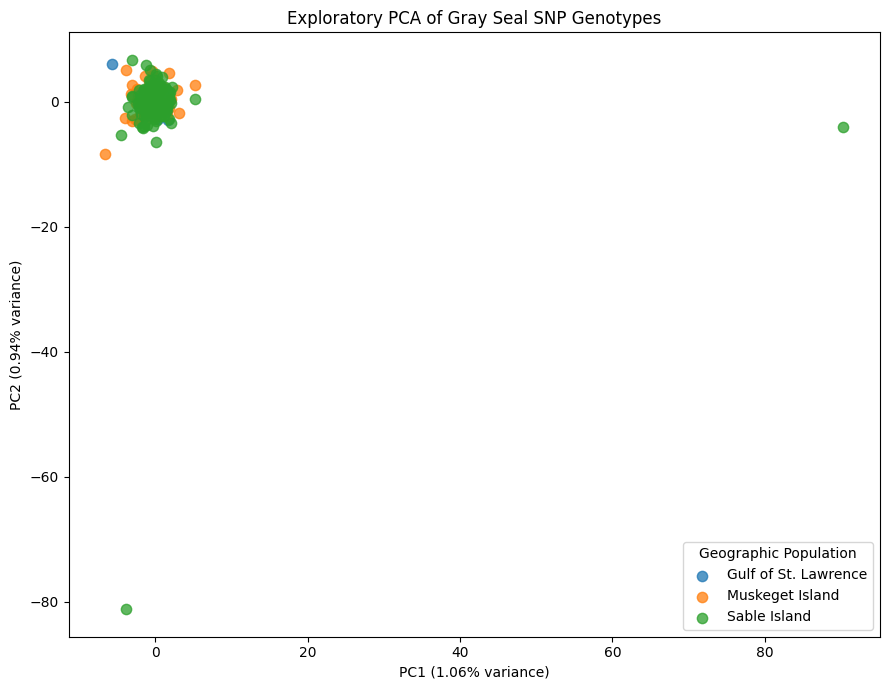

In [39]:
#use X model to visualize data
X_pca = X_model.copy()

#PCA is distance-based so we need to
# 1. Impute missing values
imputer_pca = SimpleImputer(strategy='most_frequent')
X_imputed = imputer_pca.fit_transform(X_pca)

# 2. Standardize SNP features
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X_imputed)

# fit pca on full dataset for visualization
pca = PCA(n_components=2)

pca_coordinates = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(pca_coordinates,columns=['PC1', 'PC2'],
                      index=X_model.index)

# Attach population labels
pca_df['population'] = y_population.loc[pca_df.index]

# PC's explained variance
print("Explained variance by PC1:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Explained variance by PC2:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print("Total explained variance:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# plot PCA
plt.figure(figsize=(9, 7))

for population in pca_df['population'].unique():

    subset = pca_df[pca_df['population'] == population]

    plt.scatter(subset['PC1'], subset['PC2'],
                label=population, alpha=0.75, s=55)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}% variance)")

plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}% variance)")

plt.title('Exploratory PCA of Gray Seal SNP Genotypes')
plt.legend(title='Geographic Population')
plt.tight_layout()
plt.show()

# Experiment 1 - Geographic classification

### Can SNP genotypes distinguish 3 geographic populations (Sable, Muskeget, Gulf of St. Lawrence)?

In [40]:
#Split dataset
x_exp1 = X_model.copy()
y_exp1 = y_population.copy()

x_train, x_test, y_train, y_test = train_test_split(x_exp1,y_exp1,
                          test_size=0.20,random_state=42,stratify=y_exp1)

print("Training set:", x_train.shape)
print("Test set:", x_test.shape)

print("\nTraining population distribution:")
print(y_train.value_counts())

print("\nTest population distribution:")
print(y_test.value_counts())

Training set: (201, 3281)
Test set: (51, 3281)

Training population distribution:
population
Sable Island            122
Muskeget Island          53
Gulf of St. Lawrence     26
Name: count, dtype: int64

Test population distribution:
population
Sable Island            31
Muskeget Island         14
Gulf of St. Lawrence     6
Name: count, dtype: int64


In [41]:
# Set up models
baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

log_reg = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('sclaer', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])

random_forest = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('classifier', RandomForestClassifier(n_estimators=300,
                                          random_state=42, n_jobs=-1))
])

In [42]:
# run 5-fold cross validation on train set

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

models = {'Majority Baseline': baseline,
          'Logistic Regression': log_reg,
          'Random Forest': random_forest}

results = []

for name, model in models.items():
    scores = cross_validate(model,x_train,y_train,cv=cv,
        scoring=['accuracy', 'balanced_accuracy', 'f1_macro'],n_jobs=-1)

    results.append({'Model': name,
                    'Accuracy': scores['test_accuracy'].mean(),
                    'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
                    'Macro F1': scores['test_f1_macro'].mean() })

cv_results = pd.DataFrame(results).set_index('Model')

cv_results.round(4)


,Accuracy,Balanced Accuracy,Macro F1
Model,,,
Majority Baseline,0.6071,0.3333,0.2518
Logistic Regression,0.6171,0.3607,0.3139
Random Forest,0.6071,0.3333,0.2518


In [43]:
# Modeling with PCA as feature reduction step

#Metrics to be used
scoring = {'accuracy': 'accuracy',
           'balanced_accuracy': 'balanced_accuracy',
           'f1_macro': 'f1_macro'}

# Use training data only
X_pca_train = x_train.copy()
y_pca_train = y_train.copy()

component_options = [10, 25, 50, 100]

results = []

# Compare models with and without PCA
for model_name, classifier in models.items():

    # No PCA
    steps = [('imputer', SimpleImputer(strategy='most_frequent'))]

    if model_name == 'Logistic Regression':
        steps.append(('scaler', StandardScaler()))

    steps.append(('classifier', classifier))

    pipeline = Pipeline(steps)

    scores = cross_validate(pipeline, X_pca_train, y_pca_train,
                            cv=cv, scoring=scoring, n_jobs=-1)

    results.append({
        'model': model_name,
        'approach': 'No PCA',
        'components': X_pca_train.shape[1],
        'accuracy': scores['test_accuracy'].mean(),
        'balanced_accuracy': scores['test_balanced_accuracy'].mean(),
        'macro_f1': scores['test_f1_macro'].mean() })

    # With PCA
    for n_components in component_options:

        steps = [('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()),
                 ('pca', PCA(n_components=n_components)),
                 ('classifier', classifier) ]

        pipeline = Pipeline(steps)

        scores = cross_validate(pipeline, X_pca_train, y_pca_train,
                                cv=cv, scoring=scoring, n_jobs=-1)

        results.append({
            'model': model_name,
            'approach': f'PCA ({n_components})',
            'components': n_components,
            'accuracy': scores['test_accuracy'].mean(),
            'balanced_accuracy': scores['test_balanced_accuracy'].mean(),
            'macro_f1': scores['test_f1_macro'].mean()
        })

# Display results
pca_model_results = pd.DataFrame(results)

display(pca_model_results
        .sort_values(['model', 'macro_f1'], ascending=[True, False])
        .round(4).reset_index(drop=True))


,model,approach,components,accuracy,balanced_accuracy,macro_f1
0,Logistic Regression,No PCA,3281,0.6171,0.3607,0.3139
1,Logistic Regression,PCA (100),100,0.5922,0.3362,0.2785
2,Logistic Regression,PCA (50),50,0.6023,0.3383,0.2736
3,Logistic Regression,PCA (10),10,0.6071,0.3333,0.2518
4,Logistic Regression,PCA (25),25,0.6022,0.3306,0.2505
5,Majority Baseline,No PCA,3281,0.6071,0.3333,0.2518
6,Majority Baseline,PCA (10),10,0.6071,0.3333,0.2518
7,Majority Baseline,PCA (25),25,0.6071,0.3333,0.2518
8,Majority Baseline,PCA (50),50,0.6071,0.3333,0.2518
9,Majority Baseline,PCA (100),100,0.6071,0.3333,0.2518


In [44]:
#Hyperparameter tuning

#logistic regression tuning
log_reg_grid = {'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
                'classifier__class_weight': [None, 'balanced']}

log_reg_search = GridSearchCV(estimator=log_reg,param_grid=log_reg_grid,
                              scoring=scoring,refit='f1_macro',cv=cv,n_jobs=-1)

log_reg_search.fit(x_train, y_train)


#random forest tuning
rf_grid = {'classifier__max_depth': [None, 10, 20],
           'classifier__min_samples_split': [2, 5],
           'classifier__min_samples_leaf': [1, 2, 4],
           'classifier__class_weight': [None, 'balanced']}

rf_search = GridSearchCV(estimator=random_forest,param_grid=rf_grid,
                          scoring=scoring,refit='f1_macro',cv=cv,n_jobs=1)

rf_search.fit(x_train, y_train)


#Collect cross-validation results
results = []

# Baseline

# Tuned Logistic Regression
lr_index = log_reg_search.best_index_

results.append({
    'Model': 'Tuned Logistic Regression',
    'Accuracy': log_reg_search.cv_results_['mean_test_accuracy'][lr_index],
    'Balanced Accuracy': log_reg_search.cv_results_['mean_test_balanced_accuracy'][lr_index],
    'Macro F1': log_reg_search.cv_results_['mean_test_f1_macro'][lr_index]
})

# Tuned Random Forest
rf_index = rf_search.best_index_

results.append({
    'Model': 'Tuned Random Forest',
    'Accuracy': rf_search.cv_results_['mean_test_accuracy'][rf_index],
    'Balanced Accuracy': rf_search.cv_results_['mean_test_balanced_accuracy'][rf_index],
    'Macro F1': rf_search.cv_results_['mean_test_f1_macro'][rf_index]})

tuned_results = pd.DataFrame(results).set_index('Model')


In [45]:
#display results

print("Best logistic regression parameters")
print(log_reg_search.best_params_)
print("Best CV Macro F1:", round(log_reg_search.best_score_, 4))

print("\nBest random forest parameters")
print(rf_search.best_params_)
print("Best CV Macro F1:", round(rf_search.best_score_, 4))

print("\nCross-validaation comparison")
display(tuned_results.round(4))

Best logistic regression parameters
{'classifier__C': 10, 'classifier__class_weight': 'balanced'}
Best CV Macro F1: 0.3523

Best random forest parameters
{'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Best CV Macro F1: 0.2518

Cross-validaation comparison


,Accuracy,Balanced Accuracy,Macro F1
Model,,,
Tuned Logistic Regression,0.5622,0.3677,0.3523
Tuned Random Forest,0.6071,0.3333,0.2518


Confusion Matrix:


,Gulf of St. Lawrence,Muskeget Island,Sable Island
Gulf of St. Lawrence,1,0,5
Muskeget Island,0,2,12
Sable Island,1,5,25



Classification Report:
                      precision    recall  f1-score   support

Gulf of St. Lawrence       0.50      0.17      0.25         6
     Muskeget Island       0.29      0.14      0.19        14
        Sable Island       0.60      0.81      0.68        31

            accuracy                           0.55        51
           macro avg       0.46      0.37      0.38        51
        weighted avg       0.50      0.55      0.50        51



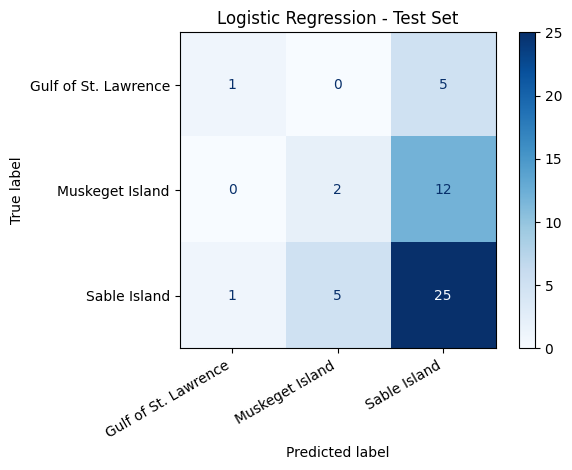

In [46]:
# Best Logistic Regression pipeline
best_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(C=10,class_weight='balanced',
                                      max_iter=5000,random_state=42)) ])

# Fit using training data only
best_lr.fit(x_train, y_train)

# Predict held-out test data
y_pred = best_lr.predict(x_test)

# Confusion matrix
class_labels = best_lr.classes_

cm = confusion_matrix(y_test,y_pred,labels=class_labels)

cm_df = pd.DataFrame(cm,index=class_labels,columns=class_labels)

print("Confusion Matrix:")
display(cm_df)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test,y_pred,zero_division=0))

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=class_labels)

disp.plot(cmap='Blues', values_format='d')
plt.title("Logistic Regression - Test Set")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


In [51]:
#Test acuracy
accuracy = best_lr.score(x_test, y_test)
print("Test set accuracy:", round(accuracy, 4))
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
print("Test set balanced accuracy:", round(balanced_accuracy, 4))

Test set accuracy: 0.549
Test set balanced accuracy: 0.372


In [47]:
# Combine test metadata and predictions
test_results = metadata.loc[x_test.index, ['population',
                            'cohort', 'cohort_id']].copy()

test_results['predicted_population'] = y_pred

test_results['correct'] = (test_results['population'] ==
                           test_results['predicted_population'])

# Summarize performance by cohort
cohort_performance = (test_results.groupby(['population', 'cohort'],
                            observed=True).agg(
                            individuals=('correct', 'size'),
                            correct=('correct', 'sum'),
                            accuracy=('correct', 'mean')).reset_index())

display(cohort_performance.round(3))

# Inspect individual predictions
display(test_results.sort_values(['population', 'cohort']))

,population,cohort,individuals,correct,accuracy
0,Gulf of St. Lawrence,2015,6,1,0.167
1,Muskeget Island,2002,2,2,1.000
2,Muskeget Island,2015_16,12,0,0.000
3,Sable Island,1973_74,7,6,0.857
4,Sable Island,1985,5,4,0.800
5,Sable Island,1998,5,5,1.000
6,Sable Island,2004,6,5,0.833
7,Sable Island,2015,8,5,0.625


,population,cohort,cohort_id,predicted_population,correct
GSL15_HgSg16-06,Gulf of St. Lawrence,2015,Gulf of St. Lawrence_2015,Sable Island,False
GSL15_HgSg16-16,Gulf of St. Lawrence,2015,Gulf of St. Lawrence_2015,Sable Island,False
GSL15_HgSg16-07,Gulf of St. Lawrence,2015,Gulf of St. Lawrence_2015,Sable Island,False
GSL15_HgSg16-12,Gulf of St. Lawrence,2015,Gulf of St. Lawrence_2015,Sable Island,False
GSL15_HgSg16-32,Gulf of St. Lawrence,2015,Gulf of St. Lawrence_2015,Sable Island,False
GSL15_HgSg16-22,Gulf of St. Lawrence,2015,Gulf of St. Lawrence_2015,Gulf of St. Lawrence,True
Mus02_UMB004,Muskeget Island,2002,Muskeget Island_2002,Muskeget Island,True
Mus02_UMB026,Muskeget Island,2002,Muskeget Island_2002,Muskeget Island,True
Mus16_Hg379,Muskeget Island,2015_16,Muskeget Island_2015_16,Sable Island,False
Mus16_Hg822,Muskeget Island,2015_16,Muskeget Island_2015_16,Sable Island,False


# Experiment 2 - Cohort-aware validation

### Can our models classify geographic populations when tested on unseen cohorts? (Sable and Muskeget to be tested; Gulf of St. Lawrence is exlcuded because it only has 1 cohort)